##Alfido Tech – Task 1: Customer Behavior Analysis

- Internship: Data Analytics Internship
- Organization: Alfido Tech
- Project: Customer Behavior Analysis
- Tools: Python, Pandas, NumPy, Matplotlib, Seaborn
- Dataset Size: 250,000 transactions
- Unique Customers: 49,673  

####Project Overview
This project focuses on analysing customer purchasing behaviour using transactional data. It explores customer segmentation, purchasing patterns, retention trends, churn indicators, and product return behaviour to identify meaningful business insights and actionable recommendations.

####Project Objectives
- Clean and prepare the customer transaction dataset.
- Analyse customer purchasing patterns and preferences.
- Segment customers using the RFM model.
- Examine customer retention through cohort analysis.
- Analyse dataset-provided churn and return indicators.
- Develop data-driven business recommendations.

### 1. Dataset Loading and Initial Inspection

The customer transaction dataset was imported into Python using Pandas. Initial inspection was performed to understand the dataset structure, identify columns, examine sample records, and check the overall dimensions of the data.

Tools Used: Pandas, NumPy.

In [ ]:
import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset successfully loaded!")
print("Dataset Shape:", df.shape)

df.head()

Saving ecommerce_customer_data_custom_ratios.csv to ecommerce_customer_data_custom_ratios.csv
Dataset successfully loaded!
Dataset Shape: (250000, 13)


,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1


### 2. Data Understanding and Data Quality Audit

The dataset contains 250,000 customer transactions and 49,673 unique customers. It includes information about purchase dates, product categories, prices, quantities, payment methods, customer demographics, returns, and churn indicators.

Initial exploration was conducted to understand:
- Dataset dimensions and column names.
- Data types and missing values.
- Unique customer records.
- Distribution of categorical variables.
- Numerical data distributions and potential anomalies.
Tools Used: Pandas, NumPy.

In [ ]:
print("DATA QUALITY AUDIT")
print("=" * 40)

print("\n1. Dataset Dimensions:")
print(df.shape)

print("\n2. Column Names:")
print(df.columns.tolist())

print("\n3. Data Types:")
print(df.dtypes)

print("\n4. Missing Values:")
print(df.isnull().sum())

print("\n5. Duplicate Records:")
print(df.duplicated().sum())

print("\n6. Unique Values:")
print(df.nunique())

print("\n7. Statistical Summary:")
display(df.describe(include="all").T)

DATA QUALITY AUDIT

1. Dataset Dimensions:
(250000, 13)

2. Column Names:
['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Age', 'Gender', 'Churn']

3. Data Types:
Customer ID                int64
Purchase Date             object
Product Category          object
Product Price              int64
Quantity                   int64
Total Purchase Amount      int64
Payment Method            object
Customer Age               int64
Returns                  float64
Customer Name             object
Age                        int64
Gender                    object
Churn                      int64
dtype: object

4. Missing Values:
Customer ID                  0
Purchase Date                0
Product Category             0
Product Price                0
Quantity                     0
Total Purchase Amount        0
Payment Method               0
Customer Age                 0
Retu

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,250000.0,NaN,NaN,NaN,25004.03624,14428.27959,1.0,12497.75,25018.0,37506.0,50000.0
Purchase Date,250000,249736,2022-05-08 12:58:55,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Category,250000,4,Clothing,75052,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Price,250000.0,NaN,NaN,NaN,254.659512,141.568577,10.0,132.0,255.0,377.0,500.0
Quantity,250000.0,NaN,NaN,NaN,2.998896,1.414694,1.0,2.0,3.0,4.0,5.0
Total Purchase Amount,250000.0,NaN,NaN,NaN,2725.370732,1442.933565,100.0,1477.0,2724.0,3974.0,5350.0
Payment Method,250000,4,Credit Card,100486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Age,250000.0,NaN,NaN,NaN,43.940528,15.350246,18.0,31.0,44.0,57.0,70.0
Returns,202404.0,NaN,NaN,NaN,0.497861,0.499997,0.0,0.0,0.0,1.0,1.0
Customer Name,250000,39920,Michael Smith,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3. Detailed Data Investigation

Before cleaning the dataset, a detailed investigation was performed to understand its structure, customer-level patterns, and potential inconsistencies.

The investigation covered:
- Comparison of redundant age columns.
- Distribution of return and churn indicators.
- Purchase date range and invalid date checks.
- Product category and payment method distributions.
- Comparison of recorded purchase amounts with calculated amounts.
- Customer transaction frequency analysis.
Objective: To identify potential data-quality issues and establish appropriate preprocessing decisions before further analysis.

In [ ]:
# Detailed Data Investigation

print("DETAILED DATA INVESTIGATION")
print("=" * 40)

# Check whether Age columns are identical
print("\n1. Age Column Comparison:")
print("Customer Age and Age identical:",
      df['Customer Age'].equals(df['Age']))

# Returns distribution
print("\n2. Returns Distribution:")
print(df['Returns'].value_counts(dropna=False))

# Churn distribution
print("\n3. Churn Distribution:")
print(df['Churn'].value_counts(dropna=False))

# Purchase date range
print("\n4. Purchase Date Range:")
dates = pd.to_datetime(df['Purchase Date'], errors='coerce')
print("Earliest:", dates.min())
print("Latest:", dates.max())
print("Invalid dates:", dates.isna().sum())

# Product category distribution
print("\n5. Product Category Distribution:")
print(df['Product Category'].value_counts())

# Payment method distribution
print("\n6. Payment Method Distribution:")
print(df['Payment Method'].value_counts())

# Check purchase amount calculation
print("\n7. Purchase Amount Investigation:")
df['Calculated Amount'] = df['Product Price'] * df['Quantity']

print("Exact matches:",
      (df['Total Purchase Amount'] == df['Calculated Amount']).sum())

print("Non-matching records:",
      (df['Total Purchase Amount'] != df['Calculated Amount']).sum())

# Customer transaction frequency
print("\n8. Customer Transaction Frequency:")
print(df['Customer ID'].value_counts().describe())

DETAILED DATA INVESTIGATION

1. Age Column Comparison:
Customer Age and Age identical: True

2. Returns Distribution:
Returns
0.0    101635
1.0    100769
NaN     47596
Name: count, dtype: int64

3. Churn Distribution:
Churn
0    200126
1     49874
Name: count, dtype: int64

4. Purchase Date Range:
Earliest: 2020-01-01 00:15:00
Latest: 2023-09-15 12:24:08
Invalid dates: 0

5. Product Category Distribution:
Product Category
Clothing       75052
Books          74912
Electronics    50185
Home           49851
Name: count, dtype: int64

6. Payment Method Distribution:
Payment Method
Credit Card    100486
PayPal          74837
Cash            49894
Crypto          24783
Name: count, dtype: int64

7. Purchase Amount Investigation:
Exact matches: 48
Non-matching records: 249952

8. Customer Transaction Frequency:
count    49673.000000
mean         5.032915
std          2.206427
min          1.000000
25%          3.000000
50%          5.000000
75%          6.000000
max         17.000000
Name: co

Statistical Summary

A statistical summary was generated to examine numerical distributions and understand the overall characteristics of the dataset.

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,250000.0,NaN,NaN,NaN,25004.03624,14428.27959,1.0,12497.75,25018.0,37506.0,50000.0
Purchase Date,250000,249736,2022-05-08 12:58:55,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Category,250000,4,Clothing,75052,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Price,250000.0,NaN,NaN,NaN,254.659512,141.568577,10.0,132.0,255.0,377.0,500.0
Quantity,250000.0,NaN,NaN,NaN,2.998896,1.414694,1.0,2.0,3.0,4.0,5.0
Total Purchase Amount,250000.0,NaN,NaN,NaN,2725.370732,1442.933565,100.0,1477.0,2724.0,3974.0,5350.0
Payment Method,250000,4,Credit Card,100486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Age,250000.0,NaN,NaN,NaN,43.940528,15.350246,18.0,31.0,44.0,57.0,70.0
Returns,202404.0,NaN,NaN,NaN,0.497861,0.499997,0.0,0.0,0.0,1.0,1.0
Customer Name,250000,39920,Michael Smith,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Purchase Amount Validation

A validation check was performed to compare the recorded purchase amount with the amount calculated using product price and quantity.

The analysis examined:
- Exact matches between recorded and calculated amounts.
- Transactions with positive and negative differences.
- Average, minimum, and maximum differences.
- Sample transaction records for further inspection.

Objective: To identify inconsistencies in purchase amount calculations and understand their impact on financial analysis.

In [ ]:
# Purchase Amount Validation

df['Calculated Amount'] = df['Product Price'] * df['Quantity']

df['Amount Difference'] = (
    df['Total Purchase Amount'] - df['Calculated Amount']
)

print("PURCHASE AMOUNT VALIDATION")
print("=" * 30)

print("\n1. Exact Matches:")
print((df['Amount Difference'] == 0).sum())

print("\n2. Positive Differences:")
print((df['Amount Difference'] > 0).sum())

print("\n3. Negative Differences:")
print((df['Amount Difference'] < 0).sum())

print("\n4. Average Difference:")
print(df['Amount Difference'].mean())

print("\n5. Minimum Difference:")
print(df['Amount Difference'].min())

print("\n6. Maximum Difference:")
print(df['Amount Difference'].max())

print("\n7. Sample Records:")
display(
    df[
        ['Product Price', 'Quantity',
         'Calculated Amount', 'Total Purchase Amount',
         'Amount Difference']
    ].head(10)
)

PURCHASE AMOUNT VALIDATION

1. Exact Matches:
48

2. Positive Differences:
221953

3. Negative Differences:
27999

4. Average Difference:
1961.734976

5. Minimum Difference:
-2330

6. Maximum Difference:
5314

7. Sample Records:


,Product Price,Quantity,Calculated Amount,Total Purchase Amount,Amount Difference
0,12,3,36,740,704
1,468,4,1872,2739,867
2,288,2,576,3196,2620
3,196,1,196,3509,3313
4,449,1,449,3452,3003
5,250,4,1000,575,-425
6,73,1,73,1896,1823
7,337,2,674,2937,2263
8,182,2,364,3363,2999
9,394,2,788,1993,1205


Further Analysis of Purchase Amount Differences

Further analysis was conducted to understand the extent of inconsistencies between recorded and calculated purchase amounts.

The analysis examined:
- Percentage of transactions with mismatched amounts.
- Average recorded purchase amount versus calculated amount.
- Average differences across product categories.
- Average differences across payment methods.

Objective: To determine whether purchase amount inconsistencies vary across product categories or payment methods.

In [ ]:
# Investigating Purchase Amount Differences

print("AMOUNT DIFFERENCE INVESTIGATION")
print("=" * 35)

print("\n1. Difference Percentage:")
print(
    (df['Amount Difference'] != 0).mean() * 100
)

print("\n2. Average Purchase Amount:")
print(df['Total Purchase Amount'].mean())

print("\n3. Average Calculated Amount:")
print(df['Calculated Amount'].mean())

print("\n4. Difference by Product Category:")

display(
    df.groupby('Product Category').agg(
        Transactions=('Customer ID', 'count'),
        Avg_Purchase=('Total Purchase Amount', 'mean'),
        Avg_Calculated=('Calculated Amount', 'mean'),
        Avg_Difference=('Amount Difference', 'mean')
    ).round(2)
)

print("\n5. Difference by Payment Method:")

display(
    df.groupby('Payment Method').agg(
        Transactions=('Customer ID', 'count'),
        Avg_Difference=('Amount Difference', 'mean')
    ).round(2)
)

AMOUNT DIFFERENCE INVESTIGATION

1. Difference Percentage:
99.9808

2. Average Purchase Amount:
2725.370732

3. Average Calculated Amount:
763.635756

4. Difference by Product Category:


,Transactions,Avg_Purchase,Avg_Calculated,Avg_Difference
Product Category,,,,
Books,74912,2735.74,760.89,1974.85
Clothing,75052,2725.21,763.22,1961.99
Electronics,50185,2721.92,766.16,1955.75
Home,49851,2713.51,765.84,1947.67



5. Difference by Payment Method:


,Transactions,Avg_Difference
Payment Method,,
Cash,49894,1959.23
Credit Card,100486,1963.14
Crypto,24783,1955.21
PayPal,74837,1963.68


### 4. Data Cleaning and Preprocessing

A separate working copy of the original dataset was created to preserve the source data. Data cleaning and preprocessing operations were performed on this copy to prepare it for further analysis.

In [ ]:
# Creating a working copy of the original dataset

df_clean = df.copy()

print("Working copy created successfully!")
print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Working copy created successfully!
Original Dataset Shape: (250000, 15)
Working Dataset Shape: (250000, 15)


In [ ]:
print("CURRENT DATASET COLUMNS")
print("=" * 30)

for col in df_clean.columns:
    print(col)

print("\nTOTAL COLUMNS:", len(df_clean.columns))

CURRENT DATASET COLUMNS
Customer ID
Purchase Date
Product Category
Product Price
Quantity
Total Purchase Amount
Payment Method
Customer Age
Returns
Customer Name
Age
Gender
Churn
Calculated Amount
Amount Difference

TOTAL COLUMNS: 15


In [ ]:
# Checking consistency between customer attributes

print("DATA CONSISTENCY CHECK")
print("=" * 35)

print("\n1. Age Columns Comparison:")
print("Identical:", df_clean['Customer Age'].equals(df_clean['Age']))

print("\n2. Customer Name Unique Count:")
print(df_clean['Customer Name'].nunique())

print("\n3. Customer ID Unique Count:")
print(df_clean['Customer ID'].nunique())

print("\n4. Gender Distribution:")
print(df_clean['Gender'].value_counts())

print("\n5. Churn Distribution:")
print(df_clean['Churn'].value_counts())

DATA CONSISTENCY CHECK

1. Age Columns Comparison:
Identical: True

2. Customer Name Unique Count:
39920

3. Customer ID Unique Count:
49673

4. Gender Distribution:
Gender
Female    125560
Male      124440
Name: count, dtype: int64

5. Churn Distribution:
Churn
0    200126
1     49874
Name: count, dtype: int64


In [ ]:
# Remove redundant Age column

df_clean.drop(columns=['Age'], inplace=True)

print("Redundant column removed successfully!")
print("Updated Dataset Shape:", df_clean.shape)

print("\nRemaining Columns:")
print(df_clean.columns.tolist())

Redundant column removed successfully!
Updated Dataset Shape: (250000, 14)

Remaining Columns:
['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Gender', 'Churn', 'Calculated Amount', 'Amount Difference']


In [ ]:
# Missing Values Analysis

missing_analysis = pd.DataFrame({
    'Missing Count': df_clean.isnull().sum(),
    'Missing Percentage': (df_clean.isnull().mean() * 100).round(2),
    'Data Type': df_clean.dtypes
})

missing_analysis = missing_analysis.sort_values(
    by='Missing Count',
    ascending=False
)

print("MISSING VALUES ANALYSIS")
print("=" * 30)

display(missing_analysis)

MISSING VALUES ANALYSIS


,Missing Count,Missing Percentage,Data Type
Returns,47596,19.04,float64
Customer ID,0,0.00,int64
Product Category,0,0.00,object
Product Price,0,0.00,int64
Quantity,0,0.00,int64
Purchase Date,0,0.00,object
Total Purchase Amount,0,0.00,int64
Payment Method,0,0.00,object
Customer Age,0,0.00,int64
Customer Name,0,0.00,object


In [ ]:
# Investigating missing values in Returns column

print("RETURNS COLUMN ANALYSIS")
print("=" * 30)

print("\nOriginal Distribution:")
print(df_clean['Returns'].value_counts(dropna=False))

print("\nMissing Values:")
print(df_clean['Returns'].isna().sum())

print("\nPercentage of Missing Values:")
print(round(df_clean['Returns'].isna().mean() * 100, 2), "%")

print("\nAvailable Values:")
print(df_clean['Returns'].dropna().unique())

RETURNS COLUMN ANALYSIS

Original Distribution:
Returns
0.0    101635
1.0    100769
NaN     47596
Name: count, dtype: int64

Missing Values:
47596

Percentage of Missing Values:
19.04 %

Available Values:
[0. 1.]


In [ ]:
# Handling missing values in Returns column

missing_before = df_clean['Returns'].isna().sum()

df_clean['Returns'] = df_clean['Returns'].fillna(-1)

print("Missing Values Treatment")
print("=" * 30)

print("Missing Values Before:", missing_before)
print("Missing Values After:", df_clean['Returns'].isna().sum())

print("\nUpdated Returns Distribution:")
print(df_clean['Returns'].value_counts().sort_index())

Missing Values Treatment
Missing Values Before: 47596
Missing Values After: 0

Updated Returns Distribution:
Returns
-1.0     47596
 0.0    101635
 1.0    100769
Name: count, dtype: int64


In [ ]:
# Convert Purchase Date to datetime

df_clean['Purchase Date'] = pd.to_datetime(
    df_clean['Purchase Date'],
    errors='coerce'
)

print("DATE CONVERSION")
print("=" * 30)

print("Data Type:", df_clean['Purchase Date'].dtype)
print("Invalid Dates:", df_clean['Purchase Date'].isna().sum())

print("\nDate Range:")
print("Start Date:", df_clean['Purchase Date'].min())
print("End Date:", df_clean['Purchase Date'].max())

DATE CONVERSION
Data Type: datetime64[ns]
Invalid Dates: 0

Date Range:
Start Date: 2020-01-01 00:15:00
End Date: 2023-09-15 12:24:08


In [ ]:
df_clean['Return Status'] = df_clean['Returns'].map({
    1: 'Returned',
    0: 'Not Returned',
    -1: 'Unknown'
})

print("Return Status Distribution:")
print(df_clean['Return Status'].value_counts(dropna=False))

Return Status Distribution:
Return Status
Not Returned    101635
Returned        100769
Unknown          47596
Name: count, dtype: int64


In [ ]:
df_clean['Purchase Year'] = df_clean['Purchase Date'].dt.year
df_clean['Purchase Month'] = df_clean['Purchase Date'].dt.month
df_clean['Purchase Month Name'] = df_clean['Purchase Date'].dt.month_name()
df_clean['Purchase Day'] = df_clean['Purchase Date'].dt.day
df_clean['Purchase Day Name'] = df_clean['Purchase Date'].dt.day_name()

print("New Features Created:")
print(df_clean[[
    'Purchase Date',
    'Purchase Year',
    'Purchase Month',
    'Purchase Month Name',
    'Purchase Day',
    'Purchase Day Name'
]].head())

New Features Created:
        Purchase Date  Purchase Year  Purchase Month Purchase Month Name  Purchase Day Purchase Day Name
0 2020-09-08 09:38:32           2020               9           September             8           Tuesday
1 2022-03-05 12:56:35           2022               3               March             5          Saturday
2 2022-05-23 18:18:01           2022               5                 May            23            Monday
3 2020-11-12 13:13:29           2020              11            November            12          Thursday
4 2020-11-27 17:55:11           2020              11            November            27            Friday


In [ ]:
customer_frequency = df_clean.groupby('Customer ID').size().reset_index(name='Total Purchases')

df_clean = df_clean.merge(
    customer_frequency,
    on='Customer ID',
    how='left'
)

print("Customer Purchase Frequency:")
print(df_clean[['Customer ID', 'Total Purchases']].head())

print("\nPurchase Frequency Summary:")
print(customer_frequency['Total Purchases'].describe())

Customer Purchase Frequency:
   Customer ID  Total Purchases
0        46251                4
1        46251                4
2        46251                4
3        46251                4
4        13593                5

Purchase Frequency Summary:
count    49673.000000
mean         5.032915
std          2.206427
min          1.000000
25%          3.000000
50%          5.000000
75%          6.000000
max         17.000000
Name: Total Purchases, dtype: float64


In [ ]:
customer_segments = customer_frequency.copy()

customer_segments['Customer Type'] = customer_segments['Total Purchases'].apply(
    lambda x: 'One-Time Customer' if x == 1 else 'Repeat Customer'
)

print("Customer Type Distribution:")
print(customer_segments['Customer Type'].value_counts())

print("\nCustomer Type Percentage:")
print(
    (customer_segments['Customer Type'].value_counts(normalize=True) * 100)
    .round(2)
)

Customer Type Distribution:
Customer Type
Repeat Customer      47988
One-Time Customer     1685
Name: count, dtype: int64

Customer Type Percentage:
Customer Type
Repeat Customer      96.61
One-Time Customer     3.39
Name: proportion, dtype: float64


In [ ]:
customer_summary = df_clean.groupby('Customer ID').agg(
    Total_Purchases=('Customer ID', 'count'),
    Total_Spending=('Total Purchase Amount', 'sum'),
    Average_Purchase_Value=('Total Purchase Amount', 'mean')
).reset_index()

print("Customer-Level Summary:")
print(customer_summary.head())

print("\nSummary Statistics:")
print(customer_summary[
    ['Total_Purchases', 'Total_Spending', 'Average_Purchase_Value']
].describe().round(2))

Customer-Level Summary:
   Customer ID  Total_Purchases  Total_Spending  Average_Purchase_Value
0            1                1            3491             3491.000000
1            2                3            7988             2662.666667
2            3                8           22587             2823.375000
3            4                4            8715             2178.750000
4            5                8           12524             1565.500000

Summary Statistics:
       Total_Purchases  Total_Spending  Average_Purchase_Value
count         49673.00        49673.00                49673.00
mean              5.03        13716.56                 2724.64
std               2.21         6840.21                  737.01
min               1.00          110.00                  110.00
25%               3.00         8719.00                 2255.71
50%               5.00        13026.00                 2728.60
75%               6.00        17966.00                 3191.20
max              17

In [ ]:
# Reference date based on the latest purchase date
reference_date = df_clean['Purchase Date'].max() + pd.Timedelta(days=1)

# Calculate RFM metrics
rfm = df_clean.groupby('Customer ID').agg(
    Recency=('Purchase Date', lambda x: (reference_date - x.max()).days),
    Frequency=('Customer ID', 'count'),
    Monetary=('Total Purchase Amount', 'sum')
).reset_index()

print("RFM Analysis - Customer Level:")
print(rfm.head())

print("\nRFM Summary:")
print(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))

RFM Analysis - Customer Level:
   Customer ID  Recency  Frequency  Monetary
0            1       58          1      3491
1            2      299          3      7988
2            3       89          8     22587
3            4      127          4      8715
4            5      171          8     12524

RFM Summary:
        Recency  Frequency  Monetary
count  49673.00   49673.00  49673.00
mean     261.42       5.03  13716.56
std      246.02       2.21   6840.21
min        1.00       1.00    110.00
25%       78.00       3.00   8719.00
50%      185.00       5.00  13026.00
75%      369.00       6.00  17966.00
max     1353.00      17.00  55339.00


In [ ]:
# Assign RFM scores using quintiles

rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine scores
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

print("RFM Scoring Results:")
print(rfm.head(10))

print("\nScore Distribution:")
print(rfm[['R_Score', 'F_Score', 'M_Score']].describe())

RFM Scoring Results:
   Customer ID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score RFM_Score
0            1       58          1      3491        5        1        1       511
1            2      299          3      7988        2        1        2       212
2            3       89          8     22587        4        5        5       455
3            4      127          4      8715        4        2        2       422
4            5      171          8     12524        3        5        3       353
5            6      463          6     15517        1        4        4       144
6            7      566          3      7835        1        1        2       112
7            8      130          6     15265        4        4        4       444
8            9      127          5     14720        4        3        3       433
9           10      230          8     20857        3        5        5       355

Score Distribution:
            R_Score       F_Score       M_Score
count  4

In [ ]:
def assign_segment(row):

    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'

    elif r >= 3 and f >= 4:
        return 'Loyal Customers'

    elif r >= 4 and f in [2, 3]:
        return 'Potential Loyalists'

    elif r >= 4 and f == 1:
        return 'Recent Customers'

    elif r <= 2 and f >= 3:
        return 'At Risk'

    elif r <= 2 and f <= 2:
        return 'Hibernating'

    else:
        return 'Others'


rfm['Customer Segment'] = rfm.apply(assign_segment, axis=1)

print("Customer Segment Distribution:")
print(rfm['Customer Segment'].value_counts())

print("\nSegment Percentage:")
print(
    (rfm['Customer Segment'].value_counts(normalize=True) * 100)
    .round(2)
)

Customer Segment Distribution:
Customer Segment
Hibernating            11125
At Risk                 8744
Champions               8692
Potential Loyalists     7219
Loyal Customers         6268
Others                  5496
Recent Customers        2129
Name: count, dtype: int64

Segment Percentage:
Customer Segment
Hibernating            22.40
At Risk                17.60
Champions              17.50
Potential Loyalists    14.53
Loyal Customers        12.62
Others                 11.06
Recent Customers        4.29
Name: proportion, dtype: float64


In [ ]:
# Merge customer segments with transaction data

df_segmented = df_clean.merge(
    rfm[['Customer ID', 'Customer Segment']],
    on='Customer ID',
    how='left'
)

# Segment-wise business analysis

segment_analysis = df_segmented.groupby('Customer Segment').agg(
    Total_Customers=('Customer ID', 'nunique'),
    Total_Purchases=('Customer ID', 'count'),
    Total_Spending=('Total Purchase Amount', 'sum'),
    Average_Purchase_Value=('Total Purchase Amount', 'mean')
).reset_index()

segment_analysis = segment_analysis.sort_values(
    by='Total_Spending',
    ascending=False
)

print("Segment-wise Business Analysis:")
print(segment_analysis.round(2).to_string(index=False))

Segment-wise Business Analysis:
   Customer Segment  Total_Customers  Total_Purchases  Total_Spending  Average_Purchase_Value
          Champions             8692            66482       189393382                 2848.79
            At Risk             8744            51968       141273167                 2718.46
    Loyal Customers             6268            43119       109432706                 2537.92
Potential Loyalists             7219            31439        85656155                 2724.52
        Hibernating            11125            30882        84336088                 2730.91
             Others             5496            20870        57127004                 2737.28
   Recent Customers             2129             5240        14124181                 2695.45


In [ ]:
# Check invalid numerical values

numeric_checks = {
    'Negative Product Price': (df_clean['Product Price'] < 0).sum(),
    'Zero Product Price': (df_clean['Product Price'] == 0).sum(),
    'Negative Quantity': (df_clean['Quantity'] < 0).sum(),
    'Zero Quantity': (df_clean['Quantity'] == 0).sum(),
    'Negative Purchase Amount': (df_clean['Total Purchase Amount'] < 0).sum(),
    'Zero Purchase Amount': (df_clean['Total Purchase Amount'] == 0).sum(),
    'Invalid Customer Age': (
        (df_clean['Customer Age'] < 1) |
        (df_clean['Customer Age'] > 100)
    ).sum()
}

print("Numerical Data Validation:")
for check, count in numeric_checks.items():
    print(f"{check}: {count}")

Numerical Data Validation:
Negative Product Price: 0
Zero Product Price: 0
Negative Quantity: 0
Zero Quantity: 0
Negative Purchase Amount: 0
Zero Purchase Amount: 0
Invalid Customer Age: 0


In [ ]:
customer_consistency = df_clean.groupby('Customer ID').agg(
    Unique_Names=('Customer Name', 'nunique'),
    Unique_Genders=('Gender', 'nunique'),
    Unique_Ages=('Customer Age', 'nunique')
)

print("Customer IDs with Multiple Names:",
      (customer_consistency['Unique_Names'] > 1).sum())

print("Customer IDs with Multiple Genders:",
      (customer_consistency['Unique_Genders'] > 1).sum())

print("Customer IDs with Multiple Ages:",
      (customer_consistency['Unique_Ages'] > 1).sum())

Customer IDs with Multiple Names: 0
Customer IDs with Multiple Genders: 0
Customer IDs with Multiple Ages: 0


In [ ]:
categorical_columns = [
    'Returns',
    'Churn',
    'Gender',
    'Product Category',
    'Payment Method'
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df_clean[col].value_counts(dropna=False))


Returns:
Returns
 0.0    101635
 1.0    100769
-1.0     47596
Name: count, dtype: int64

Churn:
Churn
0    200126
1     49874
Name: count, dtype: int64

Gender:
Gender
Female    125560
Male      124440
Name: count, dtype: int64

Product Category:
Product Category
Clothing       75052
Books          74912
Electronics    50185
Home           49851
Name: count, dtype: int64

Payment Method:
Payment Method
Credit Card    100486
PayPal          74837
Cash            49894
Crypto          24783
Name: count, dtype: int64


In [ ]:
missing_summary = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Missing Percentage': (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

print(missing_summary)

                       Missing Values  Missing Percentage
Customer ID                         0                 0.0
Purchase Date                       0                 0.0
Product Category                    0                 0.0
Product Price                       0                 0.0
Quantity                            0                 0.0
Total Purchase Amount               0                 0.0
Payment Method                      0                 0.0
Customer Age                        0                 0.0
Returns                             0                 0.0
Customer Name                       0                 0.0
Gender                              0                 0.0
Churn                               0                 0.0
Calculated Amount                   0                 0.0
Amount Difference                   0                 0.0
Return Status                       0                 0.0
Purchase Year                       0                 0.0
Purchase Month

In [ ]:
monthly_purchases = (
    df_clean
    .groupby(df_clean['Purchase Date'].dt.to_period('M'))
    .size()
    .reset_index(name='Total Purchases')
)

monthly_purchases['Purchase Date'] = (
    monthly_purchases['Purchase Date'].astype(str)
)

print(monthly_purchases.head(10))
print("\nTotal Months:", len(monthly_purchases))
print("\nHighest Purchase Month:")
print(monthly_purchases.loc[monthly_purchases['Total Purchases'].idxmax()])

print("\nLowest Purchase Month:")
print(monthly_purchases.loc[monthly_purchases['Total Purchases'].idxmin()])

  Purchase Date  Total Purchases
0       2020-01             5687
1       2020-02             5394
2       2020-03             5683
3       2020-04             5499
4       2020-05             5734
5       2020-06             5539
6       2020-07             5851
7       2020-08             5769
8       2020-09             5591
9       2020-10             5778

Total Months: 45

Highest Purchase Month:
Purchase Date      2021-03
Total Purchases       5914
Name: 14, dtype: object

Lowest Purchase Month:
Purchase Date      2023-09
Total Purchases       2672
Name: 44, dtype: object


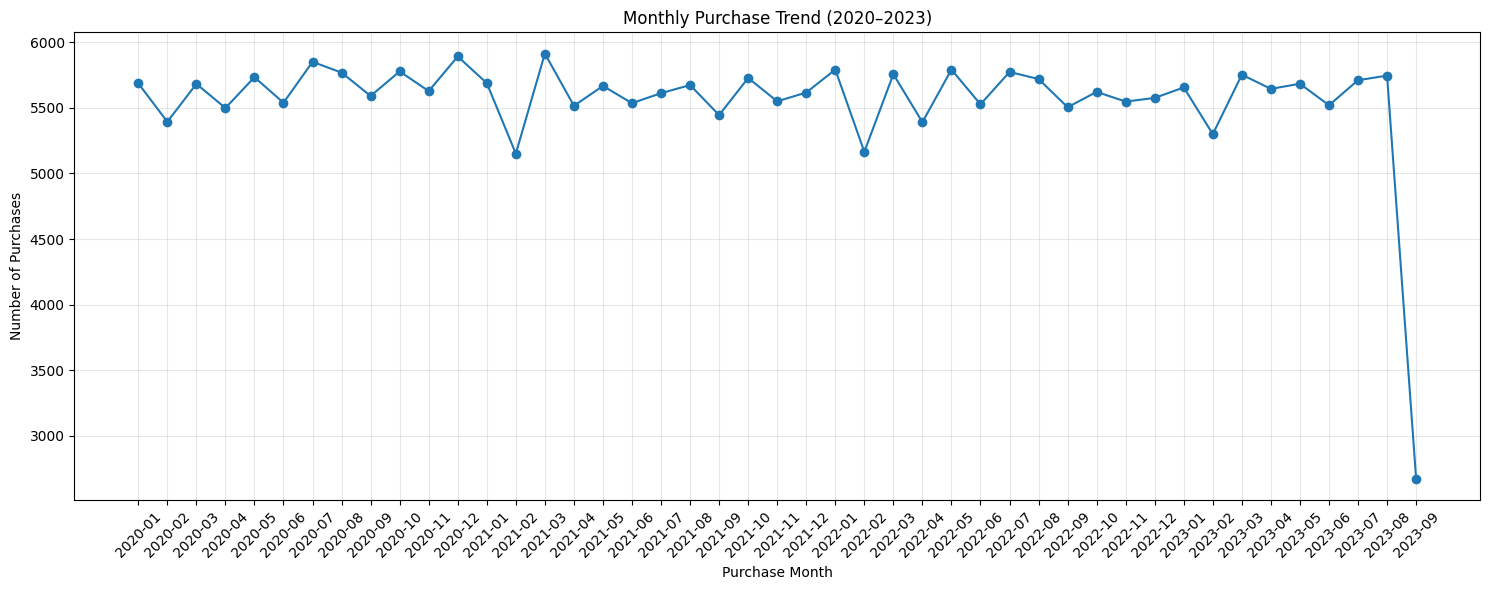

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_purchases['Purchase Date'],
    monthly_purchases['Total Purchases'],
    marker='o'
)

plt.title('Monthly Purchase Trend (2020–2023)')
plt.xlabel('Purchase Month')
plt.ylabel('Number of Purchases')

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Monthly Purchase Trend – Key Insights
- Monthly purchase activity remained relatively stable from January 2020 to August 2023, generally ranging between approximately 5,300 and 5,900 transactions
- March 2021 recorded the highest monthly purchase count, with 5,914 transactions
- No consistent long-term upward or downward trend was observed.
- September 2023 recorded 2,672 transactions; however, this month is incomplete because the dataset ends on September 15, 2023, Therefore, the lower count should not be interpreted as a confirmed decline

In [ ]:
category_analysis = df_clean.groupby('Product Category').agg(
    Total_Purchases=('Customer ID', 'count'),
    Total_Purchase_Amount=('Total Purchase Amount', 'sum'),
    Average_Purchase_Amount=('Total Purchase Amount', 'mean')
).reset_index()

category_analysis = category_analysis.sort_values(
    by='Total_Purchase_Amount',
    ascending=False
)

print(category_analysis.round(2).to_string(index=False))

Product Category  Total_Purchases  Total_Purchase_Amount  Average_Purchase_Amount
           Books            74912              204939601                  2735.74
        Clothing            75052              204532405                  2725.21
     Electronics            50185              136599467                  2721.92
            Home            49851              135271210                  2713.51


Product Category Analysis – Key Insights
- Clothing recorded the highest transaction volume with 75,052 purchases, followed closely by Books with 74,912 purchases.
- Books generated the highest total recorded purchase amount of 204,939,601.
- Home recorded the lowest transaction volume and total recorded purchase amount
- The average recorded purchase amount was relatively similar across all four product categories.
- Books showed the highest average recorded purchase amount, while Home had the lowest

Note: Amounts represent the values recorded in the dataset and are not independently verified revenue figures.

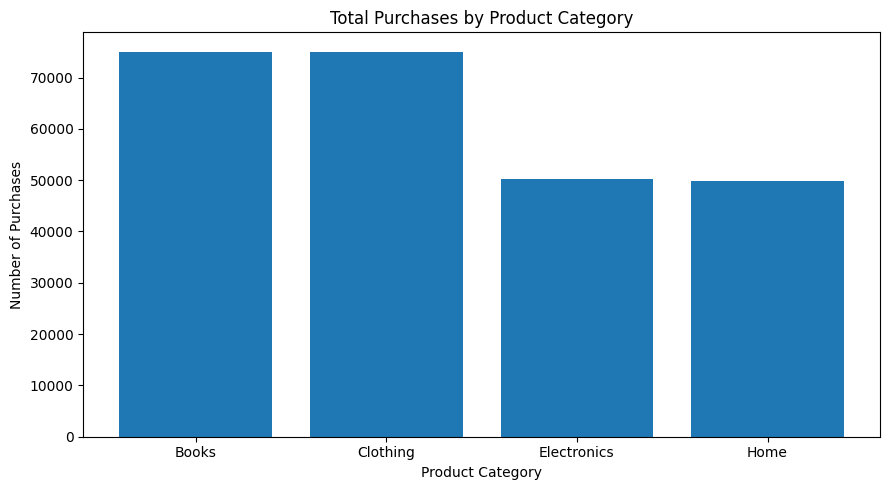

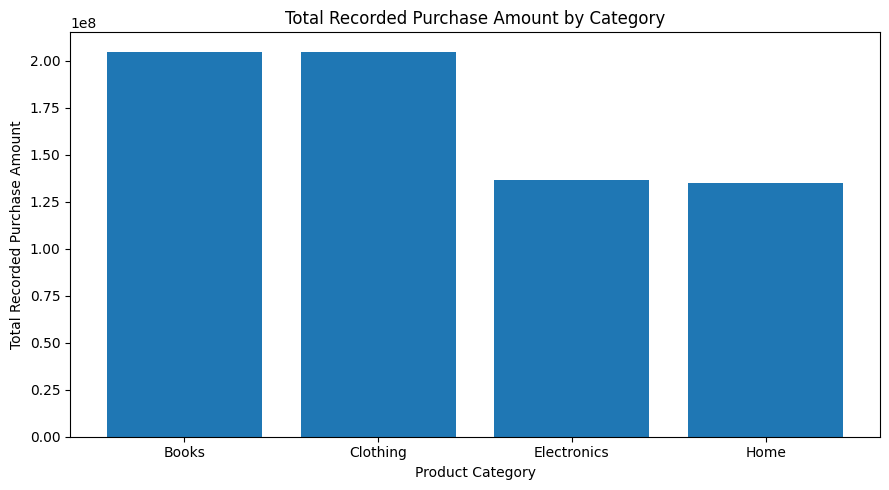

In [ ]:
import matplotlib.pyplot as plt

# Chart 1: Purchase Volume
plt.figure(figsize=(9, 5))

plt.bar(
    category_analysis['Product Category'],
    category_analysis['Total_Purchases']
)

plt.title('Total Purchases by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Purchases')
plt.tight_layout()
plt.show()


# Chart 2: Recorded Purchase Amount
plt.figure(figsize=(9, 5))

plt.bar(
    category_analysis['Product Category'],
    category_analysis['Total_Purchase_Amount']
)

plt.title('Total Recorded Purchase Amount by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Recorded Purchase Amount')
plt.tight_layout()
plt.show()

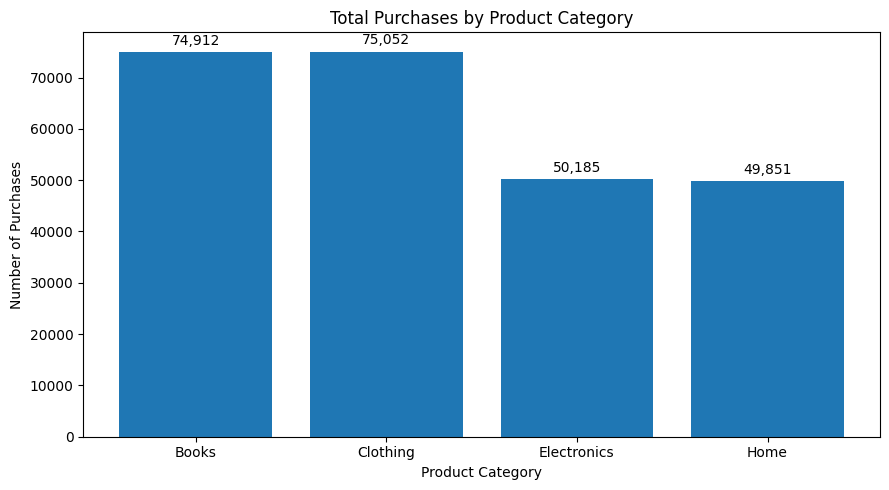

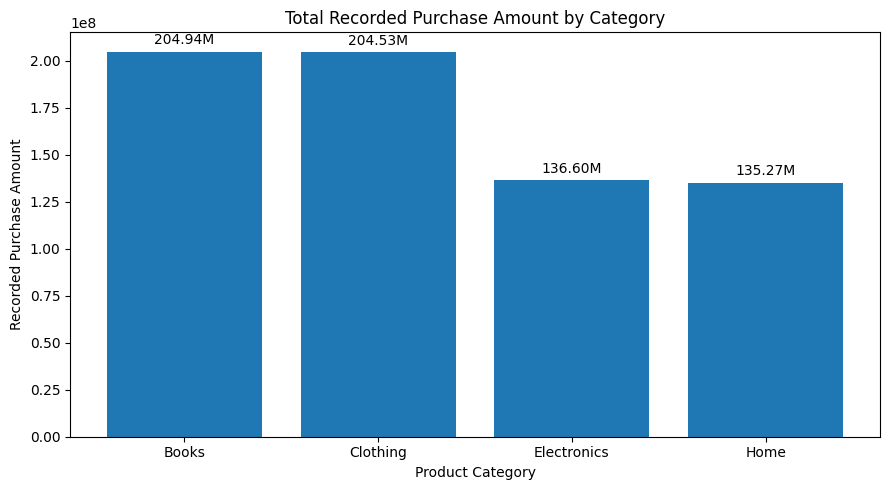

In [ ]:
# Improved Purchase Volume Chart

plt.figure(figsize=(9, 5))

bars = plt.bar(
    category_analysis['Product Category'],
    category_analysis['Total_Purchases']
)

plt.bar_label(bars, fmt='{:,.0f}', padding=3)

plt.title('Total Purchases by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Purchases')
plt.tight_layout()
plt.show()


# Improved Recorded Purchase Amount Chart

plt.figure(figsize=(9, 5))

bars = plt.bar(
    category_analysis['Product Category'],
    category_analysis['Total_Purchase_Amount']
)

plt.bar_label(
    bars,
    labels=[f'{x/1e6:.2f}M' for x in category_analysis['Total_Purchase_Amount']],
    padding=3
)

plt.title('Total Recorded Purchase Amount by Category')
plt.xlabel('Product Category')
plt.ylabel('Recorded Purchase Amount')
plt.tight_layout()
plt.show()

Business Insight:

######Books recorded the highest total purchase amount despite having slightly fewer transactions than Clothing. This indicates a marginally higher average recorded purchase amount for Books. Clothing, however, led in transaction volume. Both categories represent important areas of customer purchasing activity.

In [ ]:
payment_analysis = df_clean.groupby('Payment Method').agg(
    Total_Transactions=('Customer ID', 'count'),
    Total_Purchase_Amount=('Total Purchase Amount', 'sum'),
    Average_Purchase_Amount=('Total Purchase Amount', 'mean')
).reset_index()

payment_analysis = payment_analysis.sort_values(
    by='Total_Transactions',
    ascending=False
)

print(payment_analysis.round(2).to_string(index=False))

Payment Method  Total_Transactions  Total_Purchase_Amount  Average_Purchase_Amount
   Credit Card              100486              274152396                  2728.26
        PayPal               74837              204026613                  2726.28
          Cash               49894              135705551                  2719.88
        Crypto               24783               67458123                  2721.95


Payment Method Analysis – Key Insights
- Credit Card was the most frequently used payment method, recording 100,486 transactions
- Credit Card also accounted for the highest total recorded purchase amount of 274,152,396.
- Crypto was the least frequently used payment method, with 24,783 transactions
- Average recorded purchase amounts were relatively consistent across all payment methods, with only minor differences
- The findings indicate that payment method preference varies considerably in transaction volume, while average transaction values remain similar

Note: Purchase amounts represent the recorded values in the dataset and are not independently verified revenue figures.


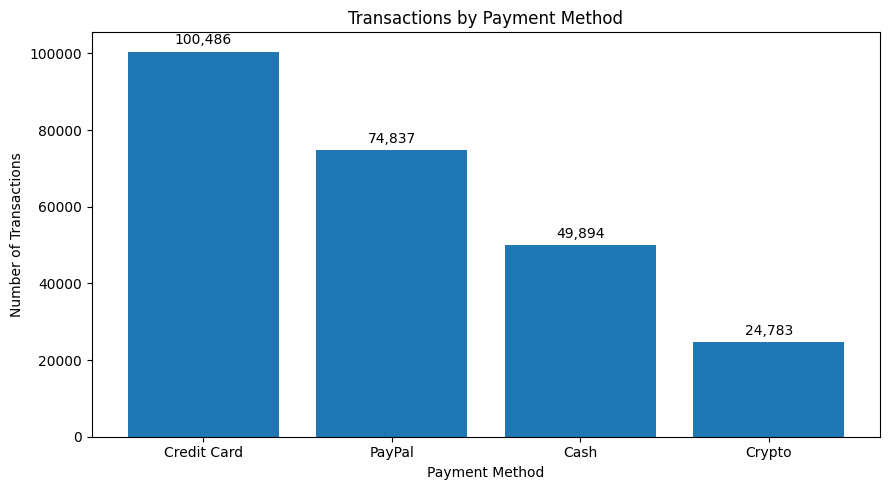

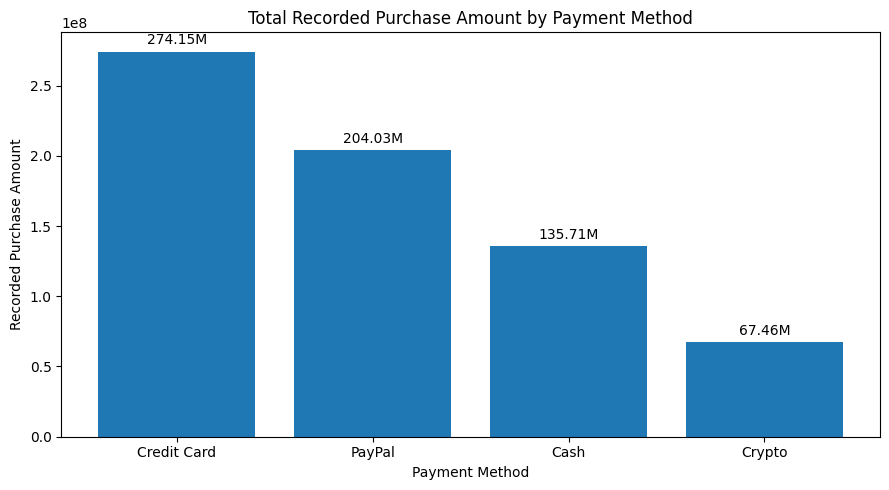

In [ ]:
# Chart 1: Transactions by Payment Method

plt.figure(figsize=(9, 5))

bars = plt.bar(
    payment_analysis['Payment Method'],
    payment_analysis['Total_Transactions']
)

plt.bar_label(bars, fmt='{:,.0f}', padding=3)

plt.title('Transactions by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()


# Chart 2: Recorded Purchase Amount by Payment Method

plt.figure(figsize=(9, 5))

bars = plt.bar(
    payment_analysis['Payment Method'],
    payment_analysis['Total_Purchase_Amount']
)

plt.bar_label(
    bars,
    labels=[
        f'{x/1e6:.2f}M'
        for x in payment_analysis['Total_Purchase_Amount']
    ],
    padding=3
)

plt.title('Total Recorded Purchase Amount by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Recorded Purchase Amount')

plt.tight_layout()
plt.show()

Payment Method Analysis – Key Insights
- Credit Card was the most frequently used payment method, accounting for 100,486 transactions.
- Credit Card also recorded the highest total purchase amount of 274.15 million.
- PayPal ranked second with 74,837 transactions.
- Crypto recorded the lowest transaction volume, with 24,783 transactions.
- Average recorded purchase amounts were relatively consistent across all payment methods, indicating only minor differences in average transaction values.

Note: Purchase amounts represent the recorded dataset values and are not independently verified revenue figures.


In [ ]:
# Create Customer Age Groups

age_bins = [0, 18, 26, 36, 46, 56, 66, 101]

age_labels = [
    'Below 18',
    '18-25',
    '26-35',
    '36-45',
    '46-55',
    '56-65',
    'Above 65'
]

df_clean['Age Group'] = pd.cut(
    df_clean['Customer Age'],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True,
    right=False
)

# Analyze Purchase Behaviour by Age Group

age_analysis = df_clean.groupby(
    'Age Group', observed=False
).agg(
    Total_Customers=('Customer ID', 'nunique'),
    Total_Purchases=('Customer ID', 'count'),
    Total_Purchase_Amount=('Total Purchase Amount', 'sum'),
    Average_Purchase_Amount=('Total Purchase Amount', 'mean')
).reset_index()

print(age_analysis.round(2).to_string(index=False))

Age Group  Total_Customers  Total_Purchases  Total_Purchase_Amount  Average_Purchase_Amount
 Below 18                0                0                      0                      NaN
    18-25             7616            38349              100404605                  2618.18
    26-35             9334            46906              124568897                  2655.71
    36-45             9362            47186              127912392                  2710.81
    46-55             9301            46753              129107480                  2761.48
    56-65             9338            47120              131874729                  2798.70
 Above 65             4722            23686               67474580                  2848.71


Age Group Analysis – Key Insights
- Customers aged 36–45 recorded the highest number of transactions, with 47,186 purchases.
- The 56–65 age group recorded the highest total recorded purchase amount of 131.87 million.
- Customers above 65 had the highest average recorded purchase amount of 2,848.71.
- Average recorded purchase amounts generally increased across older age groups.
- The dataset contains no customers below 18 years of age, based on the defined age-group boundaries.

Note: Purchase amounts represent recorded dataset values and are not independently verified revenue figures.

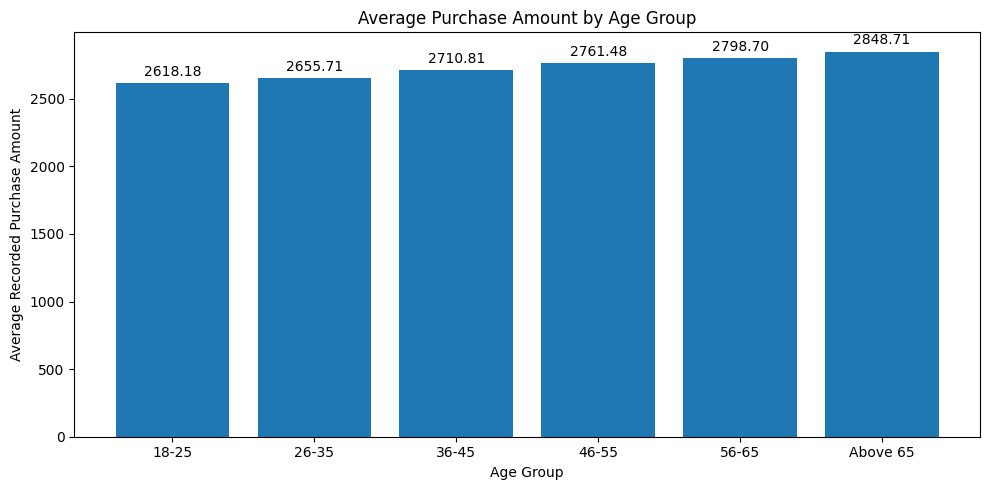

In [ ]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    age_analysis['Age Group'].astype(str),
    age_analysis['Average_Purchase_Amount']
)

plt.bar_label(bars, fmt='%.2f', padding=3)

plt.title('Average Purchase Amount by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Recorded Purchase Amount')

plt.tight_layout()
plt.show()

Age Group Analysis – Business Insight

######Average recorded purchase amount shows a gradual increasing pattern across age groups. Customers above 65 recorded the highest average purchase amount of 2,848.71, while customers aged 18–25 recorded the lowest at 2,618.18. This indicates an association between customer age and average transaction value in the dataset.

In [ ]:
gender_analysis = df_clean.groupby('Gender').agg(
    Total_Customers=('Customer ID', 'nunique'),
    Total_Purchases=('Customer ID', 'count'),
    Total_Purchase_Amount=('Total Purchase Amount', 'sum'),
    Average_Purchase_Amount=('Total Purchase Amount', 'mean')
).reset_index()

print(gender_analysis.round(2).to_string(index=False))

Gender  Total_Customers  Total_Purchases  Total_Purchase_Amount  Average_Purchase_Amount
Female            24958           125560              342462421                  2727.48
  Male            24715           124440              338880262                  2723.24


Gender-wise Purchase Analysis – Key Insights
- Female customers recorded slightly more transactions (125,560) than male customers (124,440).
- Female customers also accounted for a slightly higher total recorded purchase amount of 342.46 million.
- The average recorded purchase amount was nearly identical for both genders, with a small difference of 4.24.
- Overall, purchasing behaviour across the two gender groups was relatively similar in terms of average transaction value.

Note: These findings describe the available dataset and do not establish that gender causes differences in purchasing behaviour.

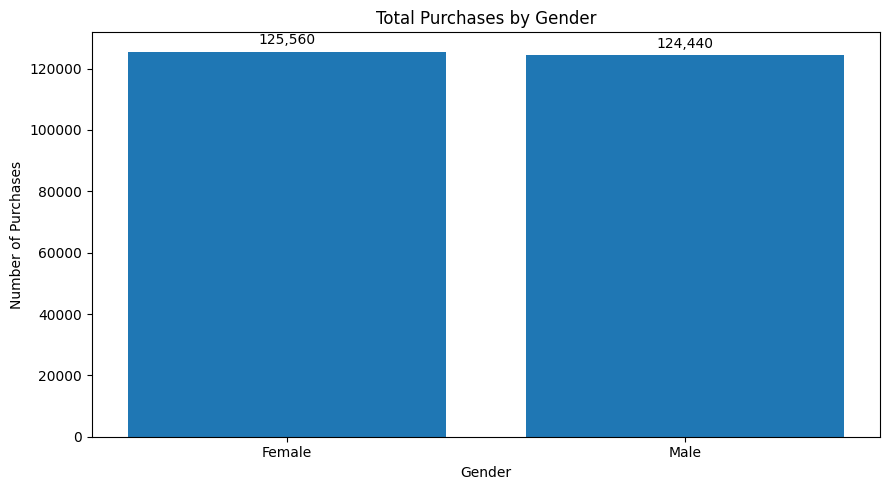

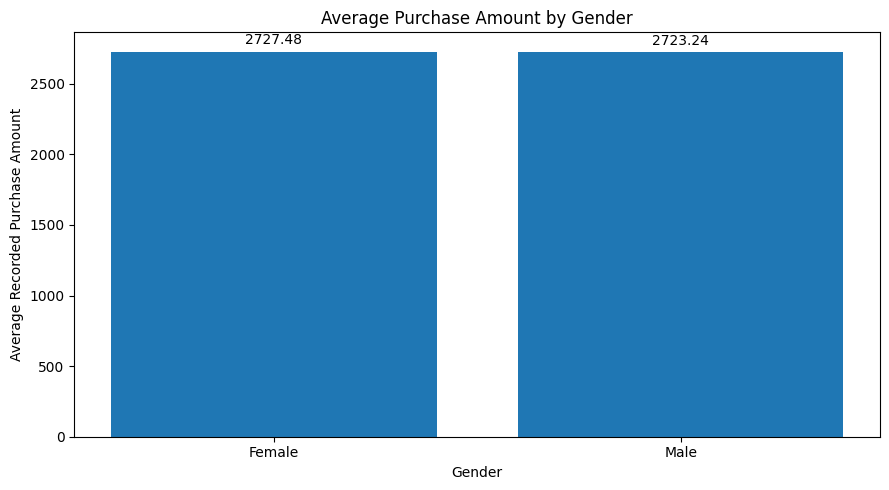

In [ ]:
# Gender-wise Purchase Comparison

plt.figure(figsize=(9, 5))

bars = plt.bar(
    gender_analysis['Gender'],
    gender_analysis['Total_Purchases']
)

plt.bar_label(bars, fmt='{:,.0f}', padding=3)

plt.title('Total Purchases by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Purchases')

plt.tight_layout()
plt.show()


# Average Purchase Amount by Gender

plt.figure(figsize=(9, 5))

bars = plt.bar(
    gender_analysis['Gender'],
    gender_analysis['Average_Purchase_Amount']
)

plt.bar_label(bars, fmt='%.2f', padding=3)

plt.title('Average Purchase Amount by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Recorded Purchase Amount')

plt.tight_layout()
plt.show()

In [ ]:
customer_type_analysis = customer_segments.groupby(
    'Customer Type'
).agg(
    Total_Customers=('Customer ID', 'nunique')
).reset_index()

customer_type_analysis['Percentage'] = (
    customer_type_analysis['Total_Customers']
    / customer_type_analysis['Total_Customers'].sum() * 100
).round(2)

print(customer_type_analysis.to_string(index=False))

    Customer Type  Total_Customers  Percentage
One-Time Customer             1685        3.39
  Repeat Customer            47988       96.61


Customer Purchase Frequency – Key Insights
- Out of 49,673 unique customers, 47,988 (96.61%) made multiple purchases.
- Only 1,685 customers (3.39%) made a single purchase during the observed period.
- The dataset shows a high proportion of repeat purchasers.
- Businesses can focus on encouraging second purchases among one-time customers while maintaining engagement with existing repeat purchasers.

In [ ]:
# Identify each customer's first purchase month

df_clean['Purchase Month'] = (
    df_clean['Purchase Date'].dt.to_period('M')
)

customer_cohort = df_clean.groupby('Customer ID').agg(
    First_Purchase_Date=('Purchase Date', 'min')
).reset_index()

customer_cohort['Cohort Month'] = (
    customer_cohort['First_Purchase_Date'].dt.to_period('M')
)

print(customer_cohort.head())
print("\nTotal Customer Cohorts:", customer_cohort['Cohort Month'].nunique())

   Customer ID First_Purchase_Date Cohort Month
0            1 2023-07-19 19:09:20      2023-07
1            2 2021-03-05 14:30:42      2021-03
2            3 2020-09-27 22:26:24      2020-09
3            4 2020-10-09 03:25:04      2020-10
4            5 2020-01-28 14:28:33      2020-01

Total Customer Cohorts: 45


In [ ]:
# Step 1: Extract purchase month for each transaction

df_clean['Purchase Month'] = (
    df_clean['Purchase Date'].dt.to_period('M')
)

# Step 2: Merge cohort month with transaction data

cohort_data = df_clean.merge(
    customer_cohort[['Customer ID', 'Cohort Month']],
    on='Customer ID',
    how='left'
)

# Step 3: Calculate cohort index

cohort_data['Cohort Index'] = (
    (cohort_data['Purchase Month'].dt.year -
     cohort_data['Cohort Month'].dt.year) * 12
    +
    (cohort_data['Purchase Month'].dt.month -
     cohort_data['Cohort Month'].dt.month)
    + 1
)

# Step 4: Count unique customers in each cohort

cohort_counts = cohort_data.groupby(
    ['Cohort Month', 'Cohort Index']
)['Customer ID'].nunique().reset_index()

cohort_counts.rename(
    columns={'Customer ID': 'Customers'},
    inplace=True
)

print(cohort_counts.head(15).to_string(index=False))

Cohort Month  Cohort Index  Customers
     2020-01             1       5376
     2020-01             2        522
     2020-01             3        578
     2020-01             4        550
     2020-01             5        544
     2020-01             6        593
     2020-01             7        583
     2020-01             8        596
     2020-01             9        580
     2020-01            10        589
     2020-01            11        565
     2020-01            12        585
     2020-01            13        610
     2020-01            14        532
     2020-01            15        594


In [ ]:
# Create cohort retention table

cohort_pivot = cohort_counts.pivot(
    index='Cohort Month',
    columns='Cohort Index',
    values='Customers'
)

# Calculate retention percentage

cohort_size = cohort_pivot.iloc[:, 0]

retention = cohort_pivot.divide(
    cohort_size,
    axis=0
) * 100

retention = retention.round(2)

print(retention.head(10).to_string())

Cohort Index     1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23     24     25     26     27     28     29     30     31     32     33     34     35     36     37     38     39     40     41     42     43     44    45
Cohort Month                                                                                                                                                                                                                                                                                                                          
2020-01       100.0   9.71  10.75  10.23  10.12  11.03  10.84  11.09  10.79  10.96  10.51  10.88  11.35   9.90  11.05  10.64  11.01  10.40  10.73  10.94  10.19  11.24  11.05  10.38  10.90   9.58  10.51  10.04  11.18  10.53  11.46  10.64  10.62   9.97  11.12  10.31  10.79  10.23  11.25  10.79  10.23  11.01  10.40  11.24  5.08
2020-02       100.0

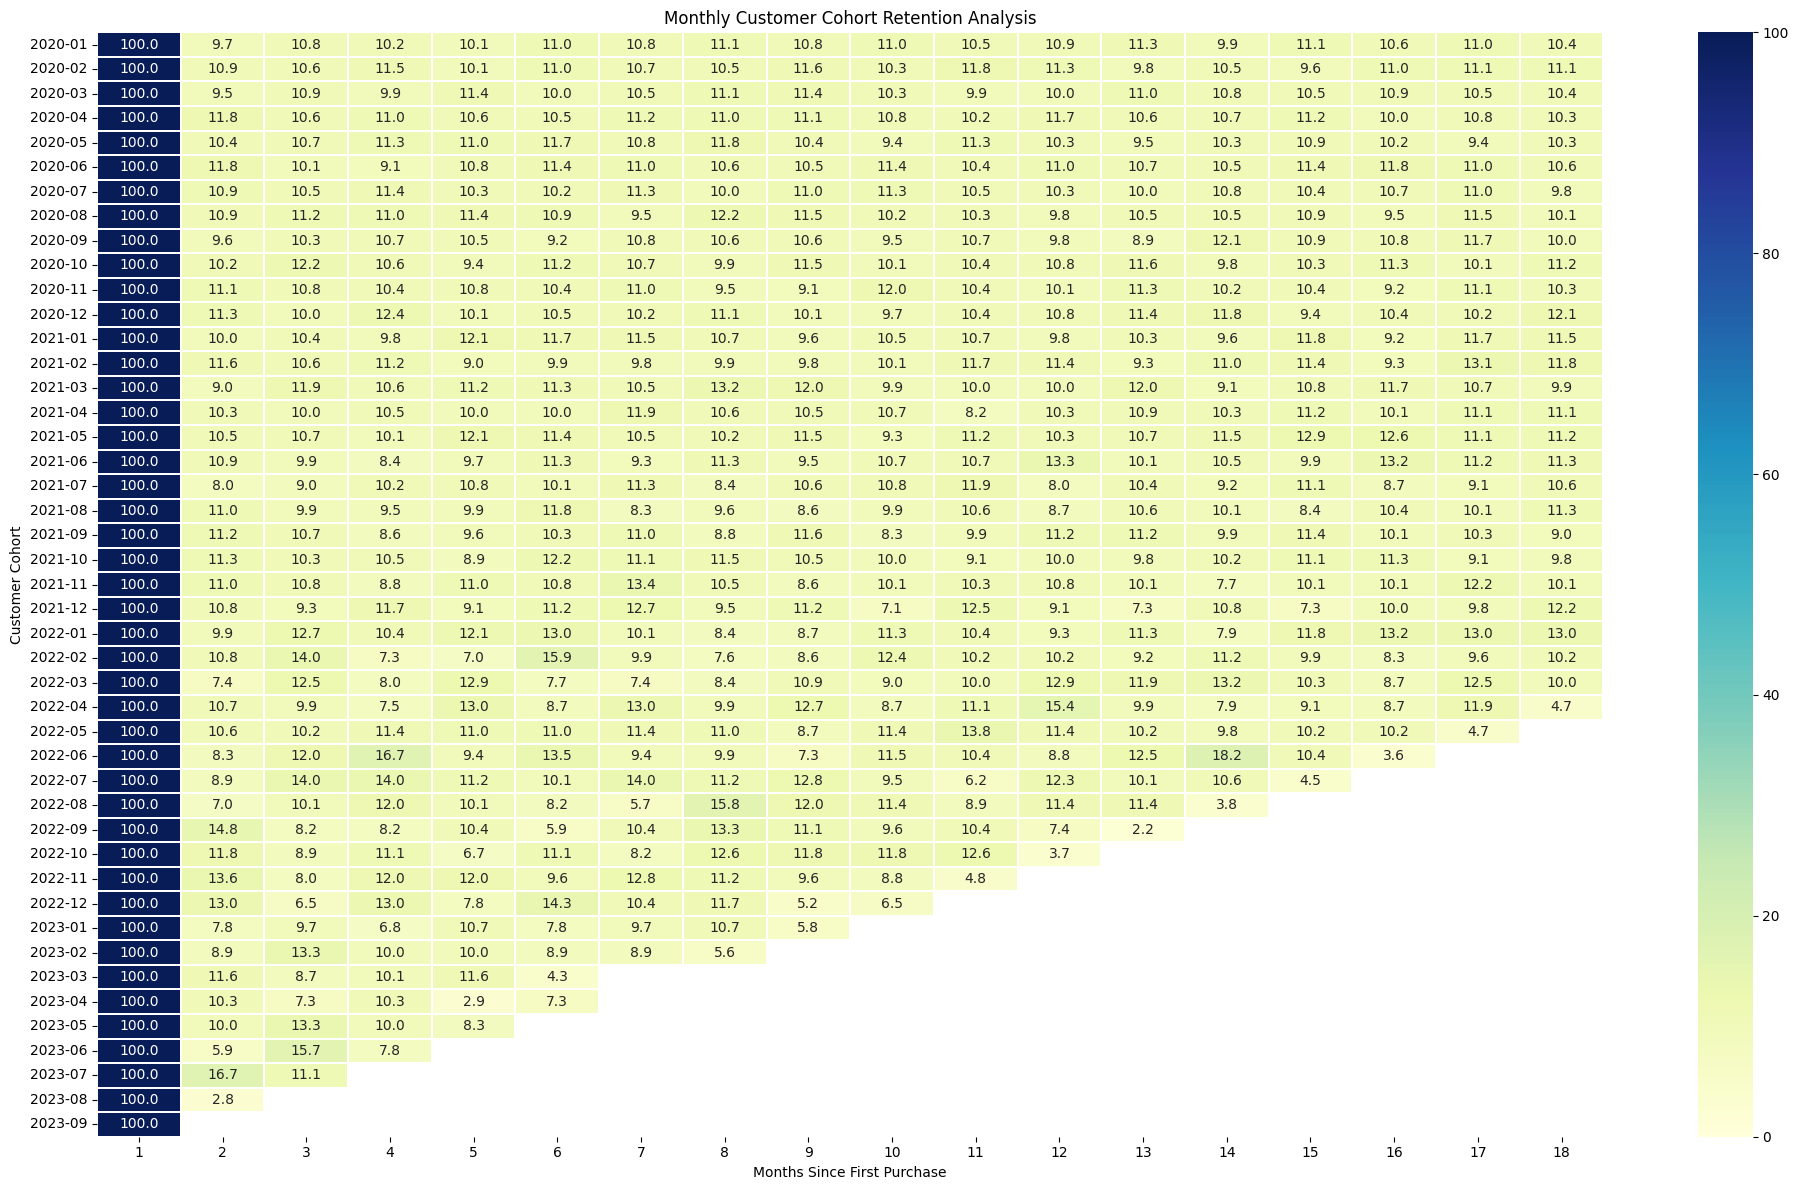

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 12))

sns.heatmap(
    retention.iloc[:, :18],
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.3,
    vmin=0,
    vmax=100
)

plt.title('Monthly Customer Cohort Retention Analysis')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Customer Cohort')

plt.tight_layout()
plt.show()

Customer Cohort Retention Analysis – Key Insights
- Cohort analysis was performed using customers' first purchase month as the acquisition period
- Month 1 retention is 100% by definition, as it represents the initial purchase month
- Most established cohorts show approximately 9–12% monthly repeat purchasing in subsequent periods.
- Retention percentages fluctuate across months, indicating that repeat purchasing is not consistent for every customer
- Recent cohorts have shorter observation periods and should not be directly compared with older cohorts for long-term retention
- The analysis highlights an opportunity to improve repeat purchasing through customer engagement and retention initiatives

Note: Cohort retention measures the percentage of customers making at least one purchase in a given period after their first purchase. It does not measure continuous or uninterrupted customer activity

In [ ]:
# Customer-level churn analysis

churn_analysis = df_clean.groupby('Customer ID').agg(
    Churn_Status=('Churn', 'first')
).reset_index()

churn_summary = churn_analysis['Churn_Status'].value_counts().reset_index()

churn_summary.columns = ['Churn Status', 'Customers']

churn_summary['Percentage'] = (
    churn_summary['Customers'] /
    churn_summary['Customers'].sum() * 100
).round(2)

print(churn_summary.to_string(index=False))

 Churn Status  Customers  Percentage
            0      39731       79.99
            1       9942       20.01


Customer Churn Analysis – Key Insights
- Out of 49,673 unique customers, 9,942 (20.01%) were marked as churned in the dataset.
- The remaining 39,731 customers (79.99%) were marked as non-churned.
- The dataset indicates that approximately one-fifth of customers have a churn status of 1.
- Businesses can investigate the purchasing behaviour of churned customers and develop targeted re-engagement strategies.

Note: Churn classification is based on the dataset-provided Churn column. The exact churn definition and observation window were not independently verified.

In [ ]:
# Churn analysis by RFM Customer Segment

customer_churn_segment = rfm.merge(
    churn_analysis,
    on='Customer ID',
    how='left'
)

segment_churn_analysis = customer_churn_segment.groupby(
    'Customer Segment'
).agg(
    Total_Customers=('Customer ID', 'nunique'),
    Churned_Customers=('Churn_Status', 'sum')
).reset_index()

segment_churn_analysis['Churn_Rate'] = (
    segment_churn_analysis['Churned_Customers'] /
    segment_churn_analysis['Total_Customers'] * 100
).round(2)

segment_churn_analysis = segment_churn_analysis.sort_values(
    by='Churn_Rate',
    ascending=False
)

print(segment_churn_analysis.to_string(index=False))

   Customer Segment  Total_Customers  Churned_Customers  Churn_Rate
Potential Loyalists             7219               1494       20.70
             Others             5496               1117       20.32
    Loyal Customers             6268               1267       20.21
        Hibernating            11125               2238       20.12
          Champions             8692               1714       19.72
   Recent Customers             2129                419       19.68
            At Risk             8744               1693       19.36


Churn Analysis by Customer Segment – Key Insights
- Potential Loyalists recorded the highest churn rate at 20.70%.
- The At Risk segment showed the lowest churn rate at 19.36%, despite its RFM-based classification.
- Churn rates across all seven customer segments remained relatively close, ranging from 19.36% to 20.70%.
- The limited variation suggests that the dataset-provided churn flag does not strongly differentiate between the RFM segments in this analysis.
- Businesses should investigate additional behavioural factors before designing segment-specific churn prevention strategies.

Note: Churn rates are calculated using the dataset-provided Churn flag. The exact churn definition and observation window are unknown.

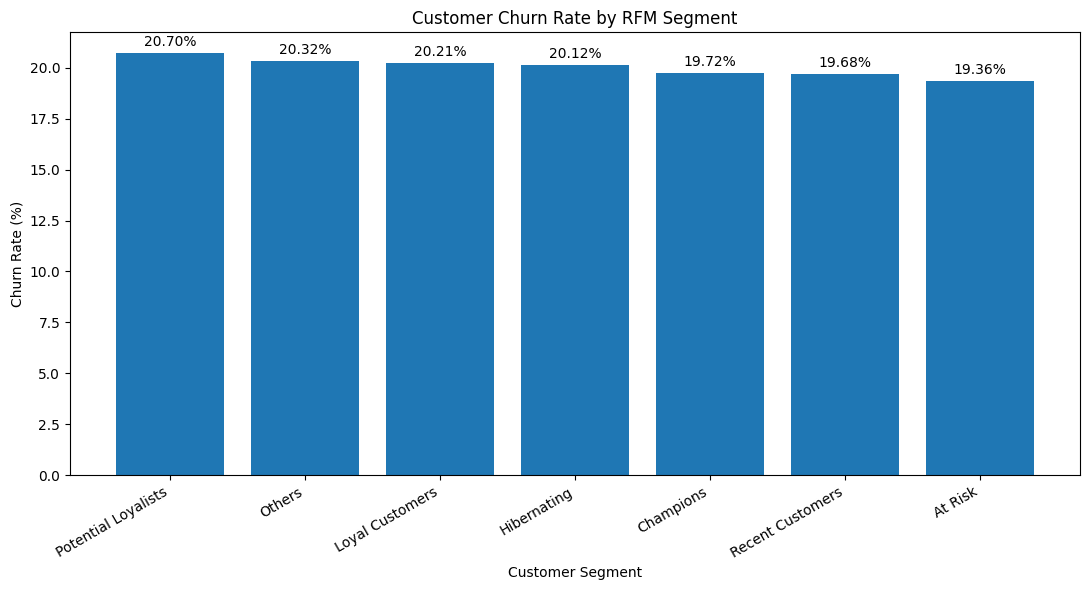

In [ ]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    segment_churn_analysis['Customer Segment'],
    segment_churn_analysis['Churn_Rate']
)

plt.bar_label(bars, fmt='%.2f%%', padding=3)

plt.title('Customer Churn Rate by RFM Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Return behaviour analysis

return_analysis = (
    df_clean.groupby('Return Status')
    .agg(
        Total_Transactions=('Customer ID', 'count'),
        Total_Purchase_Amount=('Total Purchase Amount', 'sum')
    )
    .reset_index()
)

return_analysis['Transaction_Percentage'] = (
    return_analysis['Total_Transactions']
    / return_analysis['Total_Transactions'].sum() * 100
)

print(return_analysis.round(2))

  Return Status  Total_Transactions  Total_Purchase_Amount  Transaction_Percentage
0  Not Returned              101635              276910991                   40.65
1      Returned              100769              274666386                   40.31
2       Unknown               47596              129765306                   19.04


Return Behaviour – Key Insights
- Out of 250,000 transactions, 100,769 were marked as Returned and 101,635 as Not Returned.
- Return status was unavailable for 47,596 transactions (19.04%).
- Among transactions with known return status, the return rate was 49.79%.
- The substantial proportion of unknown return records limits the reliability of overall return-rate estimates.
- Improving return-status data collection would help businesses conduct more reliable return analysis and identify potential product or customer-service issues.

In [ ]:
# Return Rate by Product Category

category_returns = (
    df_clean[df_clean['Return Status'] != 'Unknown']
    .groupby('Product Category')
    .agg(
        Total_Transactions=('Customer ID', 'count'),
        Returned_Transactions=(
            'Return Status',
            lambda x: (x == 'Returned').sum()
        )
    )
    .reset_index()
)

category_returns['Return_Rate'] = (
    category_returns['Returned_Transactions']
    / category_returns['Total_Transactions'] * 100
)

category_returns = category_returns.sort_values(
    by='Return_Rate',
    ascending=False
)

print(category_returns.round(2))

  Product Category  Total_Transactions  Returned_Transactions  Return_Rate
0            Books               60595                  30229        49.89
2      Electronics               40657                  20271        49.86
3             Home               40423                  20147        49.84
1         Clothing               60729                  30122        49.60


Category-wise Return Behaviour – Key Insights
- Books recorded the highest return rate (49.89%) among the four product categories.
- Clothing recorded the lowest return rate (49.60%).
- Return rates were relatively consistent across all categories, with a difference of only 0.29 percentage points
- No product category showed a clearly distinct return pattern in this analysis.
- Businesses should investigate additional factors, such as product quality, customer feedback and reasons for returns, before introducing category-specific return policies.

Note: Return rates are calculated only for transactions with known return status. Unknown records are excluded.

In [ ]:
# Return Rate by Payment Method

payment_returns = (
    df_clean[df_clean['Return Status'] != 'Unknown']
    .groupby('Payment Method')
    .agg(
        Total_Transactions=('Customer ID', 'count'),
        Returned_Transactions=(
            'Return Status',
            lambda x: (x == 'Returned').sum()
        )
    )
    .reset_index()
)

payment_returns['Return_Rate'] = (
    payment_returns['Returned_Transactions']
    / payment_returns['Total_Transactions'] * 100
)

payment_returns = payment_returns.sort_values(
    by='Return_Rate',
    ascending=False
)

print(payment_returns.round(2))

  Payment Method  Total_Transactions  Returned_Transactions  Return_Rate
0           Cash               40406                  20253        50.12
3         PayPal               60603                  30184        49.81
1    Credit Card               81394                  40525        49.79
2         Crypto               20001                   9807        49.03


Payment Method-wise Return Behaviour – Key Insights
- Cash transactions recorded the highest return rate at 50.12%.
- Crypto transactions recorded the lowest return rate at 49.03%.
- Return rates across payment methods showed limited variation.
- Payment method alone does not appear to strongly differentiate return behaviour in this dataset.
- Further investigation using return reasons and product-level information would be needed to identify the factors associated with returns.

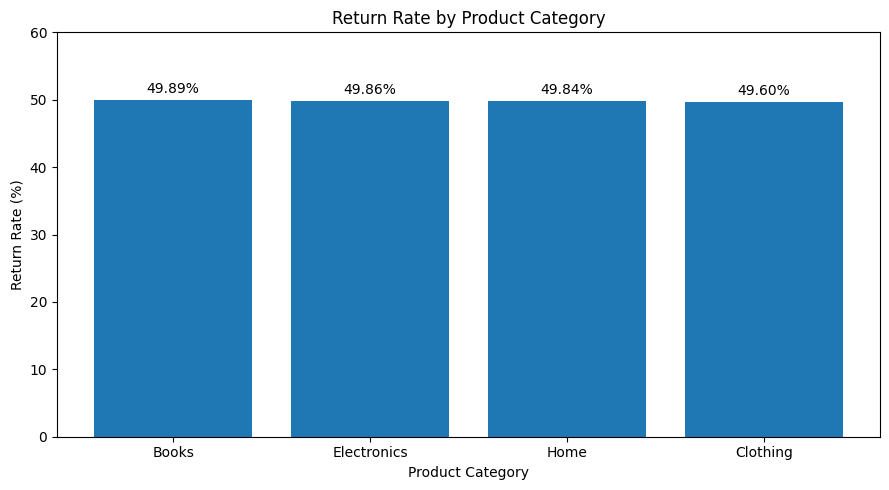

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    category_returns['Product Category'],
    category_returns['Return_Rate']
)

plt.bar_label(bars, fmt='%.2f%%', padding=3)

plt.title('Return Rate by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Return Rate (%)')

plt.ylim(0, 60)
plt.tight_layout()
plt.show()

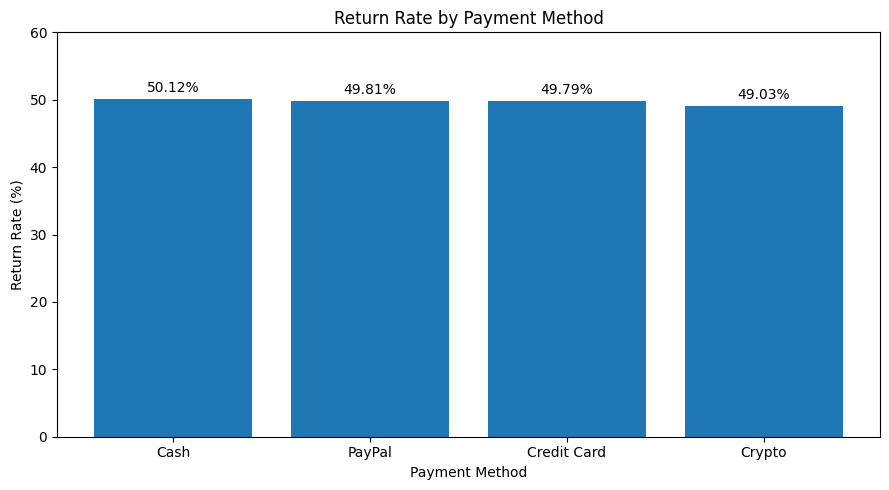

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    payment_returns['Payment Method'],
    payment_returns['Return_Rate']
)

plt.bar_label(bars, fmt='%.2f%%', padding=3)

plt.title('Return Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Return Rate (%)')
plt.ylim(0, 60)

plt.tight_layout()
plt.show()

###Key Business Insights
1. Customer Segmentation: Hibernating and At Risk customers together account for 19,869 customers (approximately 40% of the customer base), highlighting an opportunity for targeted re-engagement campaigns.
2. Repeat Purchase Behaviour: 96.61% of customers made more than one purchase during the observed dataset period. This indicates substantial repeat purchasing, although it does not independently establish customer loyalty
3. Purchase Trends: Monthly purchase volumes remained broadly stable across most complete months, with March 2021 recording the highest number of purchases (5,914).
4. Product Preferences: Clothing recorded the highest transaction count (75,052), while Books generated the highest recorded purchase amount (204,939,601).
5. Customer Age: Average recorded purchase amount generally increased across older age groups, reaching 2,848.71 for customers above 65.
6. Cohort Retention: Established cohorts showed recurring monthly purchasing, generally around 9–12% in many observed months.
7. Churn: The dataset-provided churn flag marks 20.01% of customers as churned. Its exact definition is not available, so this should be treated as a supplied indicator.
8. Returns: Return rates were nearly uniform across product categories (49.60%–49.89%) and payment methods (49.03%–50.12%). Approximately 19.04% of transactions had unknown return status.

Important data limitation: The recorded purchase amount does not consistently match Product Price × Quantity. Therefore, financial analysis uses the dataset's recorded purchase amount without assuming it represents independently verified revenue

###Business Recommendations
1. Launch Targeted Re-engagement Campaigns
Approximately 40% of customers fall into the At Risk and Hibernating RFM segments. The business should run targeted email campaigns, personalised offers, and limited-time discounts to encourage these customers to purchase again.
2. Reward High-Value Customers
Champions represent 8,692 customers with strong recency, frequency, and monetary scores. Introduce a loyalty programme, exclusive benefits, and early access to offers to retain these valuable customers.
3. Develop Age-Based Marketing Strategies
Older age groups showed higher average recorded purchase amounts. The business can test personalised product recommendations and targeted campaigns for different age groups while monitoring conversion rates.
4. Investigate Product Return Reasons
Return rates are close to 50% across all product categories. The business should collect and analyse return reasons, customer feedback, product descriptions, and quality complaints to identify the underlying causes. Unknown return status for 19.04% of transactions should also be addressed by improving data recording.
5. Strengthen Customer Retention Monitoring
Use monthly cohort retention analysis to monitor repeat purchasing behaviour. Track customer activity over time and introduce personalised reminders or relevant offers when customers become inactive.

One important point: These are proposed business actions, not proven solutions. Their effectiveness should be evaluated by tracking repeat purchase rate, customer retention, return rate, and campaign conversion.

###Data Quality Checks and Limitations
1. Missing Values
- The original dataset contained 47,596 missing values in the Returns column.
- These were represented as -1 and labelled as Unknown to avoid incorrectly classifying them as returned or not returned.
- The remaining missing values were checked after cleaning.
2. Duplicate Records
- No exact duplicate rows were identified in the dataset.
3. Redundant Columns
- The Age column contained the same information as Customer Age, so the redundant column was removed.
4. Data Consistency
- Purchase dates were successfully converted into datetime format.
- No invalid or non-positive values were identified in Product Price, Quantity, Total Purchase Amount, or customer age based on the validation rules used.
5. Purchase Amount Inconsistency
- Product Price × Quantity did not match Total Purchase Amount for most transactions.
- The recorded purchase amount was retained for analysis because the source of the discrepancy could not be established.
- Financial findings should therefore be interpreted cautiously.
6. Churn Definition
- The dataset includes a Churn indicator, but its exact business definition and observation window were not provided.
- Churn results are reported as analysis of a supplied flag, not an independently verified churn prediction.
7. Dataset Coverage
- The dataset covers January 2020 to September 15, 2023.
- September 2023 is incomplete, so it should not be directly compared with complete months.
8. Return Status
- Approximately 19.04% of transactions have unknown return status.
- Return-rate comparisons use only transactions with known return status.

In [ ]:
print("FINAL DATA VALIDATION")
print("-" * 32)

print("Dataset Shape:", df_clean.shape)
print("Unique Customers:", df_clean['Customer ID'].nunique())

print("\nMissing Values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nDuplicate Rows:", df_clean.duplicated().sum())

print("\nPurchase Date Range:")
print(df_clean['Purchase Date'].min(), "to", df_clean['Purchase Date'].max())

print("\nReturn Status:")
print(df_clean['Return Status'].value_counts())

print("\nCustomer Segments:")
print(rfm['Customer Segment'].value_counts())

FINAL DATA VALIDATION
--------------------------------
Dataset Shape: (250000, 22)
Unique Customers: 49673

Missing Values:
Series([], dtype: int64)

Duplicate Rows: 0

Purchase Date Range:
2020-01-01 00:15:00 to 2023-09-15 12:24:08

Return Status:
Return Status
Not Returned    101635
Returned        100769
Unknown          47596
Name: count, dtype: int64

Customer Segments:
Customer Segment
Hibernating            11125
At Risk                 8744
Champions               8692
Potential Loyalists     7219
Loyal Customers         6268
Others                  5496
Recent Customers        2129
Name: count, dtype: int64


In [ ]:
print(df_clean.columns.tolist())

['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Gender', 'Churn', 'Calculated Amount', 'Amount Difference', 'Return Status', 'Purchase Year', 'Purchase Month', 'Purchase Month Name', 'Purchase Day', 'Purchase Day Name', 'Total Purchases', 'Age Group']


In [ ]:
final_customer_data = df_clean.drop(
    columns=['Calculated Amount', 'Amount Difference']
).copy()

print("Final Dataset Shape:", final_customer_data.shape)
print("\nFinal Columns:")
print(final_customer_data.columns.tolist())

Final Dataset Shape: (250000, 20)

Final Columns:
['Customer ID', 'Purchase Date', 'Product Category', 'Product Price', 'Quantity', 'Total Purchase Amount', 'Payment Method', 'Customer Age', 'Returns', 'Customer Name', 'Gender', 'Churn', 'Return Status', 'Purchase Year', 'Purchase Month', 'Purchase Month Name', 'Purchase Day', 'Purchase Day Name', 'Total Purchases', 'Age Group']


In [ ]:
final_customer_data.to_csv(
    'Alfido_Customer_Behavior_Cleaned.csv',
    index=False
)

print("Final cleaned dataset exported successfully!")

Final cleaned dataset exported successfully!
